# Virtual Quantum Neural Networks — a reproduction walkthrough

**Paper:** B. Zhao, X. Zhao, Y. Li, Y. Li, G. Chiribella, *Virtual quantum
neural networks*, arXiv:2609.11327 (2026).

This notebook is the entry point to the reproduction in `papers/virtual_qnn/`.
It presents the reproduction as a scientific argument:
- what the paper claims;
- how we tested it;
- which controls could explain the results differently;
- exactly what reproduced and what did not.

**How to read it.** The notebook has two kinds of evidence, and each result is
labelled with the kind it uses:
- **Live:** small experiments run here in about 3 minutes on a laptop CPU,
  through the same `lib/` code as the full runs.
- **Stored:** results from the full multi-seed runs, read from the committed
  files in `results/` (576 sweep runs, all validated; see `LOG.md`).

| § | Content |
|---|---|
| 1 | Problem statement and paper claims |
| 2 | Data, splits, metrics, evaluation protocol |
| 3 | The mathematics of a virtual QNN |
| 4 | Known-answer sanity checks (live) |
| 5 | Model and pipeline walkthrough |
| 6 | Small live experiments |
| 7 | Headline reproduction results (stored, multi-seed) |
| 8 | Fair baseline comparison, including equal shot budgets |
| 9 | Controls and ablations |
| 10 | Robustness and uncertainty |
| 11 | Photonic (MerLin) assessment |
| 12 | Claim-level conclusion and limitations |

In [1]:
# Setup: paths, imports from lib/, plotting conventions, provenance.
import json, math, sys, time, hashlib, platform, warnings
from pathlib import Path

PROJECT_DIR = Path.cwd().resolve()
assert (PROJECT_DIR / "lib" / "runner.py").exists(), "Run this notebook from papers/virtual_qnn/"
sys.path.insert(0, str(PROJECT_DIR.parent))        # makes `virtual_qnn` importable
sys.path.insert(0, str(PROJECT_DIR.parents[1]))    # repository root (runtime_lib)

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from virtual_qnn.lib import quantum, vqem, sdp, vqc, vvqe, shot_budget, data, paper_values as paper
from virtual_qnn.lib.training import optimize
from virtual_qnn.utils import plot_style as style   # colours only (it selects the Agg backend) ...
%matplotlib inline
# ... so the inline backend is restored above.

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.precision", 4)
style.apply_style()
COLORS = style.SERIES          # fixed order: blue, orange, aqua, yellow
DTYPE = torch.complex128
DEV = torch.device("cpu")
RESULTS = PROJECT_DIR / "results"
RUNS = pd.read_csv(RESULTS / "per_run_metrics.csv")

def fingerprint(paths):
    h = hashlib.sha256()
    for p in sorted(paths):
        h.update(p.read_bytes())
    return h.hexdigest()[:12]

print(f"Python {platform.python_version()} | torch {torch.__version__} | numpy {np.__version__} | CPU: {platform.machine()}")
print(f"lib/ code fingerprint: {fingerprint(list((PROJECT_DIR / 'lib').glob('*.py')))}")
print(f"Stored per-run records: {len(RUNS)} runs from {RUNS.sweep_id.nunique()} sweeps")
NOTEBOOK_START = time.time()

Python 3.13.15 | torch 2.12.1 | numpy 2.5.3 | CPU: arm64
lib/ code fingerprint: 35c8b59660e8
Stored per-run records: 576 runs from 13 sweeps


## 1. Problem statement and paper claims

A **quantum neural network (QNN)** minimizes a loss over one parametrized
family of circuits. Physically, that means a family of CPTP maps: whatever a
shallow, noisy device can implement.

A **virtual QNN (VQNN)** enlarges that family by mixing *signed* combinations
of N circuits:

$$\mathcal M(\theta, c) = \sum_{i=1}^{N} c_i\, \mathcal C_i(\theta_i), \qquad c_i \in \mathbb R .$$

$\mathcal M$ is generally *not* a physical map (it is Hermitian-preserving),
but its expectation values can be estimated by sampling circuits and
reweighting outcomes. The paper uses N = 2 everywhere and claims gains in
*expressivity* and *noise robustness*.

| ID | Paper claim (our wording) | Paper evidence | What would weaken it |
|---|---|---|---|
| C1 | Learned 2-branch inverses mitigate unknown noise with near-optimal sampling overhead | Table I | Overhead clearly above the true optimum, or large residual error |
| C2 | The penalty α trades error for overhead, approaching the optimum | Fig. 4 | Non-monotone trend, or γ not approaching the optimum |
| C3 | A larger sampling budget compensates noisy branch circuits | Fig. 5 | Noisy branches not reaching near-zero error at a reasonable budget |
| C4 | A virtual classifier beats the conventional one under noise | Fig. 6d | No gain with γ; or the gain explained by extra parameters, by noise-free behaviour, or lost once the shot cost is counted |
| C5 | Virtual VQE gives accurate ground-state energies under noise, better than VQE | Fig. 7 | Energies far from the exact ground state; or the gain lost at equal shot budgets |

**Falsifiable research question.** *With the paper's circuits, noise levels
and training settings, does the virtual combination (budget γ > 1) improve
mitigation error, classification accuracy and ground-state energies over the
γ = 1 model, and does that improvement survive matched baselines, noiseless
controls and equal measurement budgets?*

## 2. Data, splits, metrics, and evaluation protocol

No experiment uses downloaded data. Everything is generated following the
authors' own procedures, which were recovered from their notebooks because
the paper omits them.

| Experiment | Paper item | Data | Split | Metric (direction) | Repetitions |
|---|---|---|---|---|---|
| E0 | Table I | Analytic single-qubit noise channels: depolarizing $D_p$, amplitude damping $A_q$, p, q ∈ {0.1, 0.2, 0.3} | — | Minimum sampling overhead from an SDP (exact) | 1 (deterministic) |
| E1–E2 | Table I, Fig. 4 | Same channels | — | Squared Hilbert–Schmidt (HS²) error of the virtual Choi state (↓), overhead γ (↓) | 3 seeds |
| E3 | Fig. 5 | $D_{0.2}$ | — | HS² vs fixed budget γ (↓) | 3 seeds |
| E4 | Fig. 6d | 2D circle data set: uniform in [−1, 1]², label 0 inside radius 0.7 | 200 train / 100 test, fresh per repetition | Train / test accuracy (↑) | 10 paired repetitions |
| E5 | Fig. 7 | HeH⁺ Hamiltonian (STO-3G, Jordan–Wigner, tapered to 2 qubits, PennyLane) | — | Energy (Ha) and its error vs the exact (FCI) energy (↓) | 3 seeds |

**Protocol, fixed before any result** (`LOG.md`, "Sweep Plans"):
- Optimizer: full-batch Adam with ReduceLROnPlateau, using the authors'
  learning rates and iteration counts.
- Checkpoint: the final iteration. No early stopping, and **no selection on
  test data**.
- Aggregation: mean ± population standard deviation over repetitions.
- Agreement: tolerances were declared per figure before running.

The cell below generates one repetition of the E4 data, exactly as the
classifier runs see it.

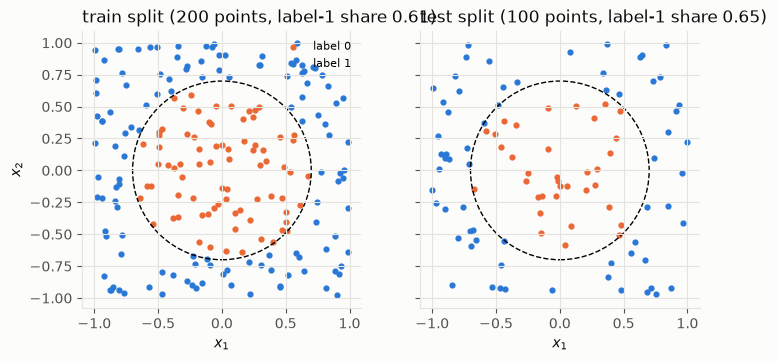

In [2]:
example = data.generate_circle_dataset(n_train=200, n_test=100, seed_data=1)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6), sharey=True)
for ax, split in zip(axes, ("train", "test")):
    x, y = example[f"{split}_x"], example[f"{split}_y"]
    for label, color in ((0, COLORS[1]), (1, COLORS[0])):
        ax.scatter(*x[y == label].T, s=12, color=color, label=f"label {label}")
    ax.add_patch(plt.Circle((0, 0), data.CIRCLE_RADIUS, fill=False, ls="--", color="k"))
    ax.set_title(f"{split} split ({len(x)} points, label-1 share {y.mean():.2f})", loc="left")
    ax.set_aspect("equal"); ax.set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$"); axes[0].legend(loc="upper right", fontsize=8)
plt.show()

The test points (right) never influence training or any hyperparameter
choice. All classifier hyperparameters are the authors' fixed values. The
classical baselines in §8 choose their learning rate on a validation split
carved from the 200 *training* points.

## 3. The mathematics of a virtual QNN

**Estimator (paper Eq. 6).** For a ±1-valued observable $P$:
- sample branch $i$ with probability $|c_i|/\gamma$, where
  $\gamma = \lVert c\rVert_1$ is the sampling overhead;
- measure $P$ on $\rho_i$, getting $o = \pm 1$;
- record $X = \gamma\,\mathrm{sign}(c_i)\,o$.

Then

$$\mathbb E[X] = \sum_i c_i \operatorname{Tr}[P\rho_i] = \operatorname{Tr}[P\sigma], \qquad \mathbb E[X^2] = \gamma^2 \;\Rightarrow\; \operatorname{Var}(\bar X_S) = \frac{\gamma^2 - \operatorname{Tr}[P\sigma]^2}{S}.$$

So the virtual estimator is unbiased, but its variance per shot is inflated
by $\gamma^2$. **Every comparison in the paper uses exact expectation values,
where this cost is invisible.** §8 makes it visible.

**Budget parameterization.** For a fixed budget γ, the paper sets
$c_1 = (1+\gamma)/2$ and $c_2 = -(\gamma-1)/2$. This gives $c_1 + c_2 = 1$
(trace preservation) and $|c_1| + |c_2| = \gamma$; γ = 1 recovers the ordinary
single-circuit model.

**The three applications:**
- **VQEM.** Drive $\sigma = \sum_i c_i (\mathbb 1 \otimes \mathcal C_i \circ \mathcal N)(\Phi^+)$
  towards the Bell state $\Phi^+$, minimizing $\lVert\Phi^+ - \sigma\rVert_2^2$
  (the paper calls this the "HS norm"). Alg. 1 adds the penalty form
  $\gamma + \alpha\,\mathrm{HS}^2$.
- **VQC.** Predict $\tilde y = \tfrac12(1 + c_1\langle Z\rangle_1 + c_2\langle Z\rangle_2)$
  and train with an MSE loss.
- **VVQE.** Minimize $\operatorname{Tr}[H\sigma] + \alpha\,|\operatorname{Tr}\,p_K(\sigma/\gamma)|$,
  where $p_K$ is a K-term Chebyshev approximation of the negativity function
  $f(x) = (|x| - x)/2$. The penalty pushes σ towards a physical state.

## 4. Known-answer sanity checks (live)

Before trusting any experiment, the building blocks must reproduce numbers
known in closed form:
1. **Noise convention.** The paper's depolarizing channel on half a Bell
   pair, without mitigation, must give HS² = 0.75 p² (= 0.03 at p = 0.2, the
   budget-1 point of the ideal curve in Fig. 5).
2. **Optimal overhead.** The App. D SDP must reproduce
   $\gamma_{\min} = (1 + p/2)/(1 - p)$ for depolarizing noise.
3. **The estimator.** Monte-Carlo sampling of Eq. 6 must be unbiased, with
   per-shot variance $\gamma^2 - \langle P\rangle^2$ (paper Eq. 7, claim C8).
4. **The Hamiltonian.** The HeH⁺ ground energy at the authors' distance
   0.8 must equal the value their notebook prints (−2.86054203541046 Ha).

In [3]:
checks = []
bell = quantum.bell_state(DTYPE)
hs = quantum.squared_hs_distance(bell, quantum.depolarize(bell, [1], 2, 0.2)).item()
checks.append(("Unmitigated HS² of D_0.2 on a Bell half", 0.75 * 0.2**2, hs))
for p in (0.1, 0.2, 0.3):
    checks.append((f"SDP minimum overhead, depolarizing p={p}", sdp.depolarizing_min_overhead_analytic(p),
                   sdp.min_sampling_overhead("depolarizing", p)["gamma_min"]))
# Monte-Carlo check of the virtual estimator at budget 2.5
rng = np.random.default_rng(0)
gamma = 2.5; c1, c2 = vqem.budget_coefficients(gamma)
def rand_state(d=4):
    a = rng.normal(size=(d, d)) + 1j * rng.normal(size=(d, d)); r = a @ a.conj().T; return r / np.trace(r)
r1, r2 = rand_state(), rand_state(); sigma_mc = c1 * r1 + c2 * r2
e1, e2 = shot_budget.pauli_expectation("XZ", r1), shot_budget.pauli_expectation("XZ", r2)
n = 400_000
second = rng.random(n) < abs(c2) / gamma
o = np.where(rng.random(n) < np.where(second, (1 + e2) / 2, (1 + e1) / 2), 1.0, -1.0)
x = gamma * np.where(second, np.sign(c2), np.sign(c1)) * o
target = shot_budget.pauli_expectation("XZ", sigma_mc)
checks.append(("Virtual estimator mean (γ=2.5)", target, x.mean()))
checks.append(("Virtual estimator per-shot variance (γ=2.5)", gamma**2 - target**2, x.var()))
fci = data.heh_tapered_hamiltonian(0.8)["fci_energy"]
checks.append(("HeH⁺ FCI energy at d = 0.8 (Ha)", -2.86054203541046, fci))
table = pd.DataFrame(checks, columns=["check", "expected", "obtained"])
table["abs. difference"] = (table.expected - table.obtained).abs()
table

,check,expected,obtained,abs. difference
0,Unmitigated HS² of D_0.2 on a Bell half,0.0300,0.0300,2.7756e-17
1,"SDP minimum overhead, depolarizing p=0.1",1.1667,1.1667,3.0537e-10
2,"SDP minimum overhead, depolarizing p=0.2",1.3750,1.3750,9.7337e-11
3,"SDP minimum overhead, depolarizing p=0.3",1.6429,1.6429,7.8425e-10
4,Virtual estimator mean (γ=2.5),-0.4513,-0.4476,3.7030e-03
5,Virtual estimator per-shot variance (γ=2.5),6.0463,6.0496,3.3289e-03
6,HeH⁺ FCI energy at d = 0.8 (Ha),-2.8605,-2.8605,8.8818e-16


**Observation.** Every check agrees to numerical precision. The Monte-Carlo
lines agree within their sampling error: the mean to within one standard
error (about 0.004) and the variance to within 0.1%.

**Inference.** The noise convention, the SDP baseline, the estimator
statistics and the Hamiltonian match the paper and its code. Claim C8 (shot
cost ∝ γ²) holds as stated.

**Remaining uncertainty.** None for these components. They validate building
blocks, not the end-to-end claims.

## 5. Model and pipeline walkthrough

All circuits use the paper's *strong entangled layer* (Fig. 3). Each layer
applies single-qubit rotations on every qubit, followed by a chain of
entangling gates. In the noisy variant, a depolarizing channel follows every
gate. The table lists the three instances, with gate choices taken from the
authors' notebooks.

In [4]:
gen = torch.Generator().manual_seed(0)
models = {
    "VQEM branch (E1–E3)": vqem.VQEMModel("depolarizing", 0.2, 5, "budget", 2.0, 2.0, (0.01, 0.02), gen, DTYPE),
    "VQC (E4, γ = 3)": vqc.VirtualQuantumClassifier(2, 2, 3.0, (0.02, 0.05), gen, DTYPE),
    "VVQE (E5, γ = 2.5)": vvqe.VirtualVQE(6, 5, 2.5, (0.01, 0.02), gen, DTYPE),
}
rows = []
for name, m in models.items():
    b = m.branches[0]
    rows.append({"model": name, "branches": len(m.branches), "qubits per branch": b.n_qubits, "layers": b.depth,
                 "rotations": "/".join(g.upper() for g in b.rotation_gates), "entangler": b.entangler.upper(),
                 "1q / 2q gate noise": f"{b.single_qubit_noise} / {b.two_qubit_noise}",
                 "trainable params": sum(p.numel() for p in m.parameters())})
pd.DataFrame(rows)

,model,branches,qubits per branch,layers,rotations,entangler,1q / 2q gate noise,trainable params
0,VQEM branch (E1–E3),2,3,5,RX/RZ,CNOT,0.01 / 0.02,60
1,"VQC (E4, γ = 3)",2,2,2,RX/RY,CZ,0.02 / 0.05,16
2,"VVQE (E5, γ = 2.5)",2,6,5,RX/RZ,CNOT,0.01 / 0.02,120


Pipeline per experiment:
- **VQEM.** The register is A (reference), B (system, hit by the unknown
  noise $\mathcal N$) and two ancillas. Each branch acts on (B, ancillas), the
  ancillas are traced out, and the two branch states are combined with
  $c_1, c_2$ and compared with $\Phi^+$.
- **VQC.** Each point is encoded on 2 qubits. Each branch outputs $\langle Z_0\rangle$,
  and the two outputs are combined into $\tilde y$.
- **VVQE.** Each branch is a 6-qubit noisy circuit whose reduced state on 2
  qubits is the trial state. The penalty below uses K = 100 Chebyshev terms,
  as in the paper.

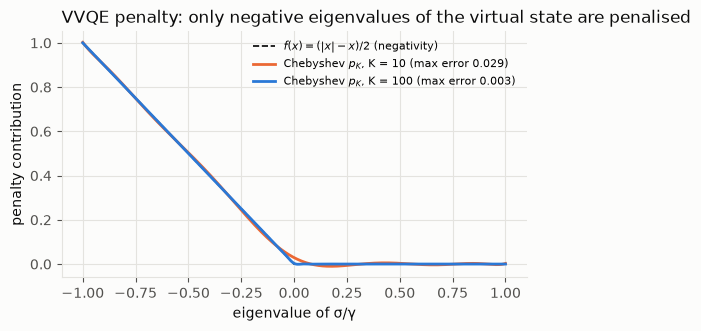

In [5]:
xs = torch.linspace(-1, 1, 401, dtype=torch.float64)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(xs, (xs.abs() - xs) / 2, color="k", lw=1.2, ls="--", label="$f(x) = (|x| - x)/2$ (negativity)")
for k, color in ((10, COLORS[1]), (100, COLORS[0])):
    coeffs = vvqe.negativity_chebyshev_coefficients(k)
    approx = sum(a * torch.cos(n * torch.arccos(xs)) for n, a in enumerate(coeffs))
    ax.plot(xs, approx, color=color, label=f"Chebyshev $p_K$, K = {k} (max error {float((approx - (xs.abs()-xs)/2).abs().max()):.3f})")
ax.set_xlabel("eigenvalue of σ/γ"); ax.set_ylabel("penalty contribution"); ax.legend(fontsize=8)
ax.set_title("VVQE penalty: only negative eigenvalues of the virtual state are penalised", loc="left")
plt.show()

## 6. Small live experiments

Each experiment below retrains one configuration at the **paper's settings
with a single seed**, through `lib/`. The seed, data and hyperparameters are
those of a stored sweep run, so a live result that matches its stored record
shows that the stored evidence (§7) comes from exactly this code. These are
single-seed illustrations. The claims are judged on the multi-seed results
in §7–§10.

### 6a. Error mitigation with a fixed budget (paper Fig. 5, noiseless branches)

In [6]:
TRAIN_VQEM2 = {"iterations": 600, "lr": 0.05, "scheduler_factor": 0.5, "scheduler_patience": 10}  # authors' settings
live_vqem = []
t0 = time.time()
for budget in (1.0, 1.2, 1.4):
    model = vqem.VQEMModel("depolarizing", 0.2, depth=5, coefficient_mode="budget", initial_t=2.0, budget=budget,
                           gate_noise=(0.0, 0.0), generator=torch.Generator().manual_seed(1), complex_dtype=DTYPE)
    optimize(model.parameters(), lambda: (model(DEV)["hs_squared"], {}), TRAIN_VQEM2)
    with torch.no_grad():
        hs_live = float(model(DEV)["hs_squared"])
    stored = RUNS.query("sweep_id == 'e3_vqem_budget_ideal' and seed == 1 and `grid--vqem-budget` == @budget").hs_squared.item()
    live_vqem.append({"budget γ": budget, "live HS² (seed 1)": hs_live, "stored HS² (seed 1)": stored,
                      "paper HS²": paper.FIG5_HS_IDEAL[paper.FIG5_BUDGET.index(budget)]})
print(f"3 trainings in {time.time() - t0:.0f} s")
pd.DataFrame(live_vqem)

3 trainings in 19 s


,budget γ,live HS² (seed 1),stored HS² (seed 1),paper HS²
0,1.0,3.0002e-02,3.0002e-02,3.0022e-02
1,1.2,6.5369e-03,6.5369e-03,6.5354e-03
2,1.4,2.2644e-12,2.2644e-12,2.3842e-07


**Observation.** Without mitigation (γ = 1) the error is the analytic
0.03. At γ = 1.2 it falls to the paper's 0.0065. At γ = 1.4, just above the
optimal overhead 1.375 from §4, it vanishes. The paper's floor of about 2e-7
is single-precision arithmetic; we use double precision. The live and stored
values agree.

### 6b. Virtual classifier, γ = 1 vs γ = 3 (paper Fig. 6d, repetition 1)

In [7]:
TRAIN_VQC = {"iterations": 150, "lr": 0.2, "scheduler_factor": 0.5, "scheduler_patience": 10}
ds = data.generate_circle_dataset(200, 100, seed_data=1)
X = {k: torch.as_tensor(v, dtype=torch.float64) for k, v in ds.items()}
live_vqc, live_vqc_models = [], {}
for budget in (1.0, 3.0):
    model = vqc.VirtualQuantumClassifier(2, 2, budget, (0.02, 0.05), torch.Generator().manual_seed(1), DTYPE)
    optimize(model.parameters(), lambda: (((model(X["train_x"]) - X["train_y"]) ** 2).mean(), {}), TRAIN_VQC)
    with torch.no_grad():
        acc = {s: vqc.reference_accuracy(model(X[f"{s}_x"]), X[f"{s}_y"]) for s in ("train", "test")}
    live_vqc_models[budget] = model
    stored = RUNS.query("sweep_id == 'e4_vqc_budget' and seed == 1 and `grid--vqc-budget` == @budget").iloc[0]
    live_vqc.append({"budget γ": budget, "params": model.n_parameters(), "live train": acc["train"], "live test": acc["test"],
                     "stored train": stored.train_accuracy, "stored test": stored.test_accuracy})
pd.DataFrame(live_vqc)

,budget γ,params,live train,live test,stored train,stored test
0,1.0,8,0.65,0.65,0.65,0.65
1,3.0,16,0.79,0.75,0.79,0.75


### 6c. Virtual VQE for HeH⁺ at d = 0.8 (paper Fig. 7)

These are the two longest live cells: about 40 s each, a 6-qubit noisy
density-matrix simulation over 300 iterations.

In [8]:
TRAIN_VVQE = {"iterations": 300, "lr": 0.2, "scheduler_factor": 0.5, "scheduler_patience": 10}
molecule = data.heh_tapered_hamiltonian(0.8)
H = torch.as_tensor(molecule["matrix"], dtype=DTYPE)
coeffs = vvqe.negativity_chebyshev_coefficients(100)
live_vvqe, live_sigmas = [], {}
for budget in (1.0, 2.5):
    t0 = time.time()
    model = vvqe.VirtualVQE(6, 5, budget, (0.01, 0.02), torch.Generator().manual_seed(1), DTYPE)
    optimize(model.parameters(), lambda: (vvqe.vvqe_terms(model.virtual_state(DEV), H, budget, 10.0, coeffs)["loss"], {}), TRAIN_VVQE)
    with torch.no_grad():
        sigma = model.virtual_state(DEV)
    live_sigmas[budget] = sigma.numpy()
    energy = float(torch.real(torch.trace(H @ sigma)))
    stored = RUNS.query("sweep_id == 'e5_vvqe' and seed == 1 and `grid--half-distance` == 0.8 and `grid--vvqe-budget` == @budget").energy.item()
    live_vvqe.append({"budget γ": budget, "live energy (Ha)": energy, "stored energy (seed 1)": stored,
                      "paper": paper.FIG7_ENERGY[budget][paper.FIG7_HALF_DISTANCE.index(0.8)],
                      "exact FCI": molecule["fci_energy"], "Hartree–Fock": molecule["hf_energy"], "seconds": round(time.time() - t0)})
pd.DataFrame(live_vvqe)

,budget γ,live energy (Ha),stored energy (seed 1),paper,exact FCI,Hartree–Fock,seconds
0,1.0,-2.3593,-2.3593,-2.3870,-2.8605,-2.8514,17
1,2.5,-2.8312,-2.8312,-2.8327,-2.8605,-2.8514,33


**Observation.** The live runs reproduce their stored records. The virtual
model (γ = 2.5) lowers the energy by about 0.47 Ha relative to noisy VQE,
moving it to the paper's value. It does **not** reach the exact energy: it
sits about 0.03 Ha above FCI and close to the Hartree–Fock value.

**Inference.** The mechanism works as described: the second, negatively
weighted branch cancels much of the noise-induced energy shift. Whether it
yields *accurate* energies depends on the reference used (§7).

## 7. Headline reproduction results (stored, multi-seed)

All values below are read from committed results (`results/`). The paper's
figure values come from the data arrays in the authors' notebooks, so the
comparison is exact rather than digitized.

### 7a. Table I — near-optimal error mitigation (claim C1)

In [9]:
cmp = json.loads((RESULTS / "comparison.json").read_text())
e0 = {r["channel"]: r for r in cmp["E0"]["rows"]}
table1 = pd.DataFrame([{
    "channel": r["channel"],
    "HS² ours (3 seeds)": f"{r['hs_mean']:.2e} ± {r['hs_std']:.0e}", "HS² paper": f"{r['paper_hs']:.2e}",
    "γ ours": f"{r['gamma_mean']:.4f} ± {r['gamma_std']:.4f}", "γ optimum (our SDP)": round(r["gamma_sdp"], 5),
    "gap to optimum": f"{r['gap_to_sdp_percent']:+.2f}%",
    "paper 'VQEM' row": r["paper_gamma_vqem_row"], "paper 'minimum' row": r["paper_gamma_minimum_row"],
} for r in cmp["E1"]["rows"]])
table1

,channel,HS² ours (3 seeds),HS² paper,γ ours,γ optimum (our SDP),gap to optimum,paper 'VQEM' row,paper 'minimum' row
0,depolarizing 0.1,1.19e-06 ± 2e-07,9.53e-07,1.1822 ± 0.0089,1.1667,+1.33%,1.1667,1.1667
1,depolarizing 0.2,1.19e-06 ± 2e-08,1.33e-06,1.3788 ± 0.0058,1.3750,+0.28%,1.3720,1.3750
2,depolarizing 0.3,1.53e-06 ± 7e-09,1.55e-06,1.6461 ± 0.0034,1.6429,+0.20%,1.6440,1.6430
3,amplitude_damping 0.1,2.65e-06 ± 4e-08,2.62e-06,1.2256 ± 0.0042,1.2222,+0.27%,1.2220,1.2180
4,amplitude_damping 0.2,3.23e-06 ± 3e-08,3.34e-06,1.4946 ± 0.0001,1.5000,-0.36%,1.5000,1.4947
5,amplitude_damping 0.3,4.43e-06 ± 3e-08,4.53e-06,1.8492 ± 0.0002,1.8571,-0.43%,1.8570,1.8490


**Observation.**
- Residual errors are about 1e-6 everywhere, as in the paper.
- Overheads are within 1% of the true optimum in 5 of 6 channels.
  Depolarizing p = 0.1 is +1.3%; its loss was still decreasing at the end of
  the authors' 800-iteration budget (`LOG.md`).
- For amplitude damping, our SDP optimum equals the paper's *VQEM* row, and
  our trained overheads (1.4946, 1.8492) equal the paper's *minimum* row.

**Inference.** The two amplitude-damping rows of Table I are swapped. The
trained overhead can dip slightly *below* the optimum only because the
inversion is approximate (HS² ≈ 1e-6).

**Remaining uncertainty.** None material.

**Claim impact.** C1 is **reproduced quantitatively**, with a labelling error
found in the paper.

### 7b. Figs. 4 and 5 — penalty and budget trade-offs (claims C2, C3)

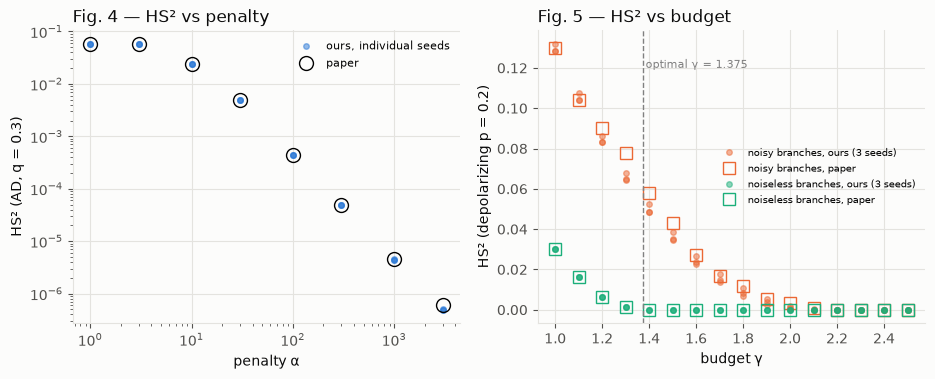

Fig. 4: γ at α = 3000: 1.8567 ± 0.0004 (optimum 1.8571; paper 1.8580)
Fig. 5: first budget with HS² < 1e-4 — noisy: ours 2.1, paper 2.3; noiseless: ours 1.4, paper 1.4


In [10]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
e2 = RUNS[RUNS.sweep_id == "e2_vqem_penalty_sweep"]
for seed, g in e2.groupby("seed"):
    a.plot(g["grid--penalty"], g.hs_squared, "o", color=COLORS[0], alpha=0.5, ms=4, label="ours, individual seeds" if seed == 1 else None)
a.plot(paper.FIG4_PENALTY, paper.FIG4_HS, "o", mfc="none", mec="k", ms=10, label="paper")
a.set_xscale("log"); a.set_yscale("log"); a.set_xlabel("penalty α"); a.set_ylabel("HS² (AD, q = 0.3)")
a.set_title("Fig. 4 — HS² vs penalty", loc="left"); a.legend(fontsize=8)
for sweep, ref, color, label in (("e3_vqem_budget_noisy", paper.FIG5_HS_NOISY, COLORS[1], "noisy branches"),
                                  ("e3_vqem_budget_ideal", paper.FIG5_HS_IDEAL, COLORS[2], "noiseless branches")):
    g = RUNS[RUNS.sweep_id == sweep]
    b.plot(g["grid--vqem-budget"], g.hs_squared, "o", color=color, alpha=0.5, ms=4, label=f"{label}, ours (3 seeds)")
    b.plot(paper.FIG5_BUDGET, ref, "s", mfc="none", mec=color, ms=9, label=f"{label}, paper")
b.axvline(1.375, color="grey", ls="--", lw=1); b.text(1.385, 0.12, "optimal γ = 1.375", fontsize=8, color="grey")
b.set_xlabel("budget γ"); b.set_ylabel("HS² (depolarizing p = 0.2)"); b.set_title("Fig. 5 — HS² vs budget", loc="left"); b.legend(fontsize=7.5)
plt.show()
gamma3000 = e2[e2["grid--penalty"] == 3000].overhead
print(f"Fig. 4: γ at α = 3000: {gamma3000.mean():.4f} ± {gamma3000.std(ddof=0):.4f} (optimum 1.8571; paper 1.8580)")
print(f"Fig. 5: first budget with HS² < 1e-4 — noisy: ours {cmp['E3']['noisy']['first_budget_hs_below_1e-4']}, paper {cmp['E3']['noisy']['paper_first_budget_hs_below_1e-4']}; "
      f"noiseless: ours {cmp['E3']['ideal']['first_budget_hs_below_1e-4']}, paper {cmp['E3']['ideal']['paper_first_budget_hs_below_1e-4']}")

**Observation.**
- **Fig. 4** is reproduced point for point: HS² ratio 0.83–1.00 to the
  paper, and γ within 0.0013.
- **Fig. 5, noiseless curve:** identical to the paper.
- **Fig. 5, noisy curve:** within ±0.01 at 15 of 16 budgets. It reaches
  HS² < 1e-4 at γ = 2.1, against 2.3 in the paper.

**Inference.** The one outlier (γ = 1.3, −0.012) is within the spread
between the authors' own two runs of this sweep: their notebook stores 0.0646
at γ = 1.3, while their figure plots 0.0777.

**Claim impact.**
- C2 is **reproduced quantitatively**.
- C3 is **reproduced** at exact values, but its cost (γ² more shots) is
  untested (§8).

### 7c. Fig. 6d — virtual quantum classifier (claim C4)

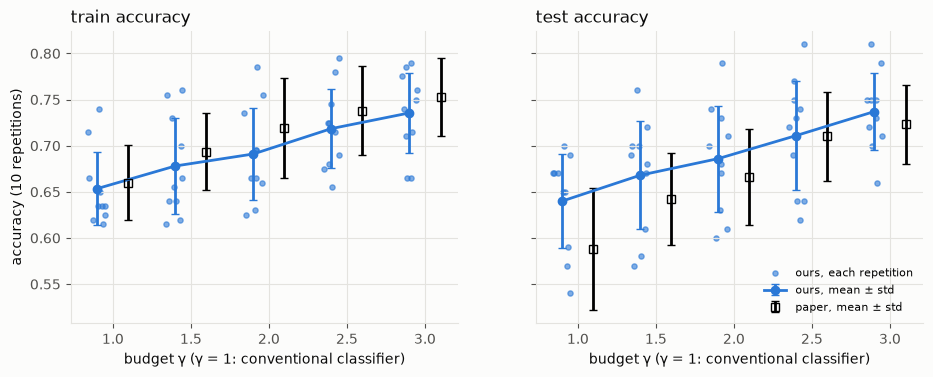

Paired test accuracy γ=3 − γ=1: +0.097 ± 0.041, t = 7.51, p = 3.7e-05, improved in 10/10 repetitions


In [11]:
e4 = RUNS[RUNS.sweep_id == "e4_vqc_budget"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, split, pmean, pstd in ((axes[0], "train", paper.FIG6_TRAIN_MEAN, paper.FIG6_TRAIN_STD), (axes[1], "test", paper.FIG6_TEST_MEAN, paper.FIG6_TEST_STD)):
    jitter = np.random.default_rng(0).uniform(-0.06, 0.06, len(e4))
    ax.scatter(e4["grid--vqc-budget"] + jitter - 0.1, e4[f"{split}_accuracy"], s=14, color=COLORS[0], alpha=0.6, label="ours, each repetition")
    agg = e4.groupby("grid--vqc-budget")[f"{split}_accuracy"].agg(["mean", lambda s: s.std(ddof=0)])
    ax.errorbar(agg.index - 0.1, agg["mean"], yerr=agg.iloc[:, 1], fmt="o-", color=COLORS[0], capsize=3, label="ours, mean ± std")
    ax.errorbar(np.array(paper.FIG6_BUDGET) + 0.1, pmean, yerr=pstd, fmt="s", mfc="none", color="k", capsize=3, label="paper, mean ± std")
    ax.set_xlabel("budget γ (γ = 1: conventional classifier)"); ax.set_title(f"{split} accuracy", loc="left")
axes[0].set_ylabel("accuracy (10 repetitions)"); axes[1].legend(fontsize=8)
plt.show()
p = cmp["E4"]["paired_budget3_vs_budget1_test"]
print(f"Paired test accuracy γ=3 − γ=1: {p['mean_difference']:+.3f} ± {p['std_difference']:.3f}, t = {p['t_statistic']:.2f}, "
      f"p = {p['p_value_two_sided']:.1e}, improved in {p['pairs_improved']}/{p['n_pairs']} repetitions")

**Observation.** All ten of our means are within one paper standard
deviation, and accuracy rises steadily with γ: +0.097 test accuracy from
γ = 1 to γ = 3, with all 10 paired repetitions improving.

**Inference.** The paper's Fig. 6d is reproduced. *Why* accuracy improves is
a separate question, answered by the controls in §8–§9.

**Remaining uncertainty.** Our data sets match the paper's only in
distribution, because the authors did not record their seeds.

**Claim impact.** The metric is **reproduced**; the explanation is tested
below.

### 7d. Fig. 7 — virtual VQE (claim C5)

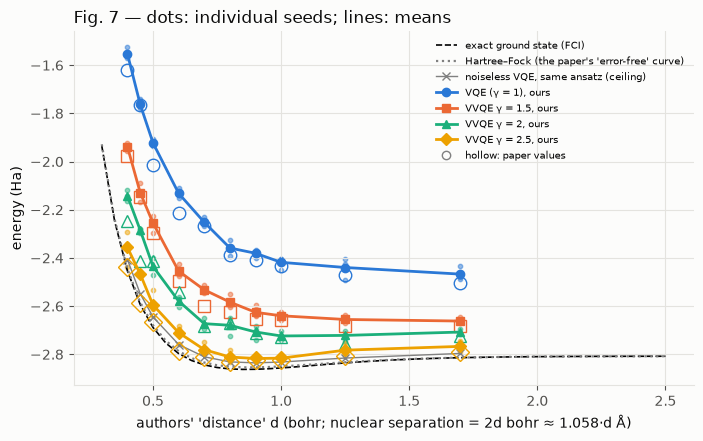

E(γ=2.5) < E(γ=1.5) < E(γ=1) at 10/10 distances; within 0.02 Ha of the paper: 13/40 points (means), 24/40 (best of 3 seeds)
Error vs FCI at γ = 2.5, mean over seeds: d=0.4: 0.097, d=0.45: 0.127, d=0.5: 0.093, d=0.6: 0.087, d=0.7: 0.063, d=0.8: 0.049, d=0.9: 0.045, d=1.0: 0.041, d=1.25: 0.053, d=1.7: 0.047


In [12]:
e5 = RUNS[RUNS.sweep_id == "e5_vvqe"]
grid = np.linspace(0.3, 2.5, 45)
ref = [data.heh_tapered_hamiltonian(float(round(d, 4))) for d in grid]
noiseless = RUNS[RUNS.sweep_id == "e5_vqe_noiseless"].groupby("grid--half-distance").energy.mean()
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(grid, [r["fci_energy"] for r in ref], "k--", lw=1.2, label="exact ground state (FCI)")
ax.plot(grid, [r["hf_energy"] for r in ref], ":", color="grey", lw=1.6, label="Hartree–Fock (the paper's 'error-free' curve)")
ax.plot(noiseless.index, noiseless.values, "x-", color="grey", lw=1, label="noiseless VQE, same ansatz (ceiling)")
for i, budget in enumerate((1.0, 1.5, 2.0, 2.5)):
    g = e5[e5["grid--vvqe-budget"] == budget]
    ax.scatter(g["grid--half-distance"], g.energy, s=10, color=COLORS[i], alpha=0.5)
    m = g.groupby("grid--half-distance").energy.mean()
    ax.plot(m.index, m.values, "-", marker=style.MARKERS[i], color=COLORS[i], label=("VQE (γ = 1)" if budget == 1 else f"VVQE γ = {budget:g}") + ", ours")
    ax.plot(paper.FIG7_HALF_DISTANCE, paper.FIG7_ENERGY[budget], linestyle="none", marker=style.MARKERS[i], mfc="none", mec=COLORS[i], ms=9)
ax.plot([], [], "o", mfc="none", mec="grey", label="hollow: paper values")
ax.set_xlabel("authors' 'distance' d (bohr; nuclear separation = 2d bohr ≈ 1.058·d Å)"); ax.set_ylabel("energy (Ha)")
ax.legend(fontsize=7.5, loc="upper right"); ax.set_title("Fig. 7 — dots: individual seeds; lines: means", loc="left")
plt.show()
e5c = cmp["E5"]
print(f"E(γ=2.5) < E(γ=1.5) < E(γ=1) at {e5c['points_ordered']}/10 distances; within 0.02 Ha of the paper: "
      f"{e5c['n_agree_mean']}/40 points (means), {e5c['n_agree_best_of_3']}/40 (best of 3 seeds)")
print("Error vs FCI at γ = 2.5, mean over seeds: " + ", ".join(
    f"d={r['half_distance']}: {r['abs_error_fci_mean']:.3f}" for r in e5c["rows"] if r["budget"] == 2.5))

**Observation.**
- The ordering by budget reproduces at all 10 distances.
- Our *mean* energies sit 0.00–0.13 Ha above the paper's points: 13 of 40
  points are within 0.02 Ha, rising to 24 of 40 if the best of 3 seeds is
  taken.
- Most importantly, the paper's "error-free" dashed curve is **Hartree–Fock**,
  not the exact energy. Against the exact (FCI) energy, VVQE at γ = 2.5 is
  still 0.04–0.13 Ha too high.
- Even the *noiseless* VQE with the same ansatz stops 0.02–0.05 Ha above FCI.

**Inference.** VVQE recovers roughly the noiseless performance of its circuit
family, which is consistent with the error-mitigation mechanism. The
remaining error is a limitation of the ansatz and its optimization, which no
budget can remove.

**Remaining uncertainty.** The paper's points beat all of our seeds at some
distances. §10 shows this is not a matter of training length, and not fully
explained by reporting the best of several runs.

**Claim impact.** "VVQE improves on noisy VQE" is **reproduced in trend**.
"Accurate ground-state energies" is **not supported**. The paper's metric is
**not reproduced quantitatively**.

## 8. Fair baseline comparison

The paper's only baseline for C4 and C5 is the **same circuit at γ = 1**.
The table checks it, and our added baselines, dimension by dimension. A
dimension is called "matched" only where it really is.

| Dimension | VQC γ > 1 vs paper baseline (γ = 1) | vs parameter-matched noisy QC (depth 4) | vs classical MLP 2-4-1 | VVQE vs noisy VQE (γ = 1) |
|---|---|---|---|---|
| Information / inputs | matched (same encoding) | matched | matched (raw x₁, x₂) | matched (same H) |
| Parameter count | **not matched** (16 vs 8) | matched (16 vs 16) | approximately matched (16 vs 17) | **not matched** (2 vs 1 circuits) |
| Training data | matched (same 200 points per repetition) | matched | matched | n/a |
| Optimization steps | matched (150 Adam iterations) | matched | matched (150) | matched (300) |
| Tuning budget | matched (authors' fixed settings) | matched | **not matched**: LR chosen from 3 values on a validation split | matched |
| Compute / measurements | **not matched**: γ² more shots for equal precision | not matched (same) | MLP needs no shots | **not matched**: γ² more shots |
| Evaluation protocol | matched (same test set, same rule) | matched | matched (sigmoid threshold) | matched (energy vs FCI) |

The bold rows are why the paper's comparisons are not fair on their own.
Parameters are handled by the depth-4 control (§9). Measurements are handled
here: we re-evaluate the *trained* models with the paper's estimator at an
**equal number of measurement shots**, using the exact formulas from §3. The
comparison rule was frozen before any equal-shot number was computed
(`LOG.md`, "Phase 5 Comparison Plan").

First, a live version of the method, applied to the two classifiers trained
in §6b:

In [13]:
def branch_z(model, x):
    with torch.no_grad():
        rho = vqc.encode_points(x, model.n_qubits, model.complex_dtype)
        return [torch.real(torch.einsum("bij,ji->b", br(rho), model.observable)).numpy() for br in model.branches]
live_shots = []
for budget, model in live_vqc_models.items():
    z = branch_z(model, X["test_x"]); coeffs = [model.c1, model.c2][: len(z)]
    mu = sum(c * zi for c, zi in zip(coeffs, z))
    for S in (1, 10, 100, 1000, math.inf):
        live_shots.append({"budget γ": budget, "shots per prediction S": S,
                           "expected test accuracy": shot_budget.expected_accuracy(mu, ds["test_y"], sum(abs(c) for c in coeffs), S)})
pd.DataFrame(live_shots).pivot(index="shots per prediction S", columns="budget γ", values="expected test accuracy")

budget γ,1.0,3.0
shots per prediction S,,
1.0,0.5286,0.5247
10.0,0.5928,0.5935
100.0,0.6357,0.6593
1000.0,0.6462,0.7203
inf,0.6500,0.7500


Next, the full stored comparison: all 10 repetitions for the classifiers, and
every trained VVQE model (10 distances × 3 seeds).

E4: expected test accuracy at S shots per prediction (10 paired repetitions)


,gate QC γ=1 (8 params),gate QC depth 4 (16 params),noiseless gate QC γ=1,gate VQC γ=3 (16 params)
S=1,0.530 ± 0.005,0.524 ± 0.007,0.534 ± 0.007,0.526 ± 0.003
S=3,0.544 ± 0.007,0.535 ± 0.010,0.549 ± 0.011,0.538 ± 0.004
S=10,0.586 ± 0.018,0.572 ± 0.022,0.590 ± 0.021,0.587 ± 0.014
S=30,0.603 ± 0.024,0.580 ± 0.026,0.606 ± 0.028,0.612 ± 0.014
S=100,0.624 ± 0.036,0.591 ± 0.044,0.622 ± 0.038,0.655 ± 0.020
S=1000,0.638 ± 0.052,0.603 ± 0.069,0.631 ± 0.046,0.715 ± 0.032
S=inf,0.640 ± 0.051,0.607 ± 0.071,0.632 ± 0.049,0.737 ± 0.041


Paired difference, gate VQC γ=3 minus baseline (✓ = significant gain, p < 0.05)


,vqc|gamma=1.0,param_matched|gamma=1.0,noiseless_qc|gamma=1.0
S=1,-0.004 (p=0.037),+0.001 (p=0.56),-0.008 (p=0.021)
S=3,-0.005 (p=0.07),+0.003 (p=0.35),-0.011 (p=0.038)
S=10,+0.001 (p=0.75),+0.015 (p=0.0033) ✓,-0.002 (p=0.73)
S=30,+0.009 (p=0.24),+0.033 (p=0.00059) ✓,+0.006 (p=0.56)
S=100,+0.031 (p=0.016) ✓,+0.064 (p=0.0003) ✓,+0.033 (p=0.042) ✓
S=1000,+0.076 (p=0.00013) ✓,+0.112 (p=0.00019) ✓,+0.084 (p=0.0002) ✓
S=inf,+0.097 (p=3.7e-05) ✓,+0.130 (p=0.00021) ✓,+0.105 (p=3.1e-05) ✓


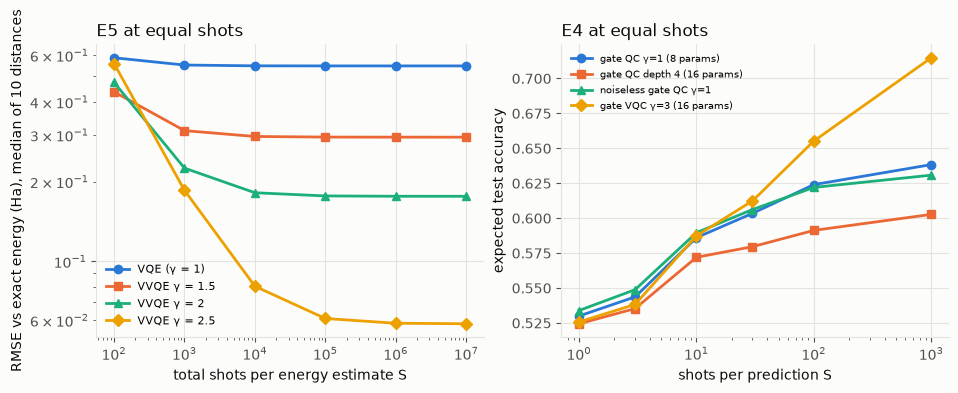

E5: distances (out of 10) where VVQE γ=2.5 beats VQE: S=100: 7, S=1000: 10, S=10000: 10, S=100000: 10


In [14]:
fair = json.loads((RESULTS / "fair_comparison.json").read_text())
acc = {f"{r['model']}|{r['shots']}": r for r in fair["e4_equal_shots_per_prediction"]["rows"]}
shots = ["1", "3", "10", "30", "100", "1000", "inf"]
names = {"vqc|gamma=1.0": "gate QC γ=1 (8 params)", "param_matched|gamma=1.0": "gate QC depth 4 (16 params)",
         "noiseless_qc|gamma=1.0": "noiseless gate QC γ=1", "vqc|gamma=3.0": "gate VQC γ=3 (16 params)"}
print("E4: expected test accuracy at S shots per prediction (10 paired repetitions)")
display(pd.DataFrame({names[m]: [f"{acc[f'{m}|{s}']['mean']:.3f} ± {acc[f'{m}|{s}']['std']:.3f}" for s in shots] for m in names}, index=[f"S={s}" for s in shots]))
tests = fair["e4_equal_shots_per_prediction"]["paired_tests"]
print("Paired difference, gate VQC γ=3 minus baseline (✓ = significant gain, p < 0.05)")
display(pd.DataFrame({c.split(" - ")[1]: [f"{tests[f'{c}|S={s}']['mean_difference']:+.3f} (p={tests[f'{c}|S={s}']['p_value_two_sided']:.2g}){' ✓' if tests[f'{c}|S={s}']['advantage_at_equal_shots'] else ''}" for s in shots]
                      for c in ("vqc|gamma=3.0 - vqc|gamma=1.0", "vqc|gamma=3.0 - param_matched|gamma=1.0", "vqc|gamma=3.0 - noiseless_qc|gamma=1.0")}, index=[f"S={s}" for s in shots]))
rows = fair["e5_equal_total_shots"]["rows"]; dec = fair["e5_equal_total_shots"]["decisions"]
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
for i, budget in enumerate((1.0, 1.5, 2.0, 2.5)):
    r = [x for x in rows if x["budget"] == budget]
    a.plot([x["shots"] for x in r], [x["median_rmse_over_distances"] for x in r], marker=style.MARKERS[i], color=COLORS[i], label="VQE (γ = 1)" if budget == 1 else f"VVQE γ = {budget:g}")
a.set_xscale("log"); a.set_yscale("log"); a.set_xlabel("total shots per energy estimate S"); a.set_ylabel("RMSE vs exact energy (Ha), median of 10 distances")
a.set_title("E5 at equal shots", loc="left"); a.legend(fontsize=8)
for i, (m, label) in enumerate(names.items()):
    b.plot([1, 3, 10, 30, 100, 1000], [acc[f"{m}|{s}"]["mean"] for s in shots[:-1]], marker=style.MARKERS[i], color=COLORS[i], label=label)
b.set_xscale("log"); b.set_xlabel("shots per prediction S"); b.set_ylabel("expected test accuracy"); b.set_title("E4 at equal shots", loc="left"); b.legend(fontsize=7.5)
plt.show()
print("E5: distances (out of 10) where VVQE γ=2.5 beats VQE: " + ", ".join(f"S={s}: {dec[f'gamma=2.5|S={s}']['distances_virtual_better']}" for s in (100, 1000, 10000, 100000)))

**Observation.**
- **E4.** At equal shots per prediction, the virtual classifier (γ = 3)
  significantly beats the conventional classifier only from about **100
  shots** per prediction. At 1–10 shots it is equal or slightly worse.
  Against the parameter-matched baseline it wins from 10 shots onwards.
- **E5.** VVQE beats noisy VQE at every distance once **S ≳ 10³** shots per
  energy estimate. At 10² shots, γ = 2.5 wins at only 7 of 10 distances.
- Both behaviours follow from the estimator: noisy VQE has a large *bias*
  (about 0.55 Ha) that extra shots cannot remove, while the virtual estimator
  has a larger *variance* that extra shots can.

**Inference.** The paper's advantages are real but *conditional*: they hold
only when enough measurements are available, a condition the paper never
states. For the classifier, the gain also survives matching the parameter
count.

**Remaining uncertainty.**
- The models were trained with exact expectations; training under shot noise
  could change the picture.
- C3 (error mitigation) cannot be tested at equal shots, because the paper
  gives no protocol for measuring its HS² metric.

**Claim impact.** C4 and C5 are **weakened to conditional claims**: they
hold only with S ≳ 10² or 10³ shots.

## 9. Controls and ablations

The paper explains the classifier gain as **noise robustness**. Credible
alternatives are:
1. extra parameters;
2. a richer output function: a signed combination of two circuits can
   reshape and rescale the decision function even without noise.

The controls separate these, on the same 10 data sets as §7c.

In [15]:
base = RUNS[RUNS.sweep_id == "e4_vqc_baselines"].copy()
base["model"] = base["grid--classical-kind"].fillna(base["grid--config"].str.extract(r"e4_vqc_(\w+)\.json")[0])
labels = {"param_matched": "noisy QC, depth 4 (16 params)", "noiseless": "noiseless QC γ=1 (8 params)", "mlp": "classical MLP 2-4-1 (17 params)", "logistic": "logistic regression (3 params)"}
rows = []
for budget in (1.0, 3.0):
    g = e4[e4["grid--vqc-budget"] == budget]
    rows.append({"model": f"noisy VQC γ={budget:g} ({int(g.n_parameters.iloc[0])} params)", "test mean": g.test_accuracy.mean(), "test std": g.test_accuracy.std(ddof=0),
                 "per repetition": " ".join(f"{v:.2f}" for v in g.sort_values("seed").test_accuracy)})
for key, label in labels.items():
    g = base[base.model == key]
    rows.append({"model": label, "test mean": g.test_accuracy.mean(), "test std": g.test_accuracy.std(ddof=0),
                 "per repetition": " ".join(f"{v:.2f}" for v in g.sort_values("seed").test_accuracy)})
pd.DataFrame(rows)

,model,test mean,test std,per repetition
0,noisy VQC γ=1 (8 params),0.640,0.0514,0.65 0.67 0.67 0.67 0.59 0.54 0.70 0.57 0.65 0.69
1,noisy VQC γ=3 (16 params),0.737,0.0412,0.75 0.81 0.73 0.75 0.70 0.71 0.72 0.66 0.75 0.79
2,"noisy QC, depth 4 (16 params)",0.607,0.0714,0.63 0.67 0.68 0.73 0.57 0.49 0.53 0.60 0.54 0.63
3,noiseless QC γ=1 (8 params),0.632,0.0489,0.65 0.68 0.65 0.59 0.62 0.53 0.69 0.58 0.65 0.68
4,classical MLP 2-4-1 (17 params),0.924,0.0265,0.87 0.92 0.96 0.95 0.92 0.90 0.90 0.95 0.93 0.94
5,logistic regression (3 params),0.587,0.0846,0.65 0.60 0.73 0.41 0.60 0.63 0.58 0.50 0.53 0.64


**Observation.**
- Adding parameters to a single circuit (depth 4, 16 parameters) does **not**
  help (0.61).
- Removing all gate noise does **not** help either: the noiseless classifier
  scores 0.63, the same as the noisy one (0.64).
- The noisy virtual classifier (0.74) beats both: by +0.13 over the
  parameter-matched circuit and +0.105 over the noiseless one (paired
  p ≤ 2.1e-4).
- A 17-parameter classical MLP reaches 0.92.

**Inference.** The gain is **not noise robustness**, since there is nothing
to recover relative to the noiseless model. It is also not raw parameter
count. It comes from the richer combined readout. The task itself is
classically easy.

**Other ablations shown in §7.**
- Fig. 4: penalty α. HS² decreases monotonically as γ approaches the
  optimum.
- Fig. 5: noisy vs noiseless branches. Noisy branches need a larger budget
  (2.1 vs 1.4) for the same error.
- Fig. 7: the noiseless-VQE ceiling, which caps what mitigation can achieve.

**Claim impact.** C4's metric reproduces, but its stated *explanation* does
**not survive the controls**.

## 10. Robustness and uncertainty

**Seed variability.** The standard deviations over seeds are reported
everywhere above. They are tiny for E1–E3 (convex-like problems), 0.04–0.06
for E4 accuracy, and 0.01–0.06 Ha for E5 energies, where the landscape is
multimodal.

**The Fig. 7 gap was diagnosed with predeclared hypotheses.**
- **H1:** the paper reports the best of several runs.
- **H2:** 300 iterations are too few.

Both were tested on 6 representative points (stored diagnostic sweeps).

In [16]:
diag10 = RUNS[RUNS.sweep_id == "e5_diag_best_of_10"]; diag600 = RUNS[RUNS.sweep_id == "e5_diag_600_iterations"]
rows = []
for (d, budget), g in diag10.groupby(["grid--half-distance", "grid--vvqe-budget"]):
    ref = paper.FIG7_ENERGY[budget][paper.FIG7_HALF_DISTANCE.index(d)]
    long = diag600[(diag600["grid--half-distance"] == d) & (diag600["grid--vvqe-budget"] == budget)].energy
    short3 = g[g.seed <= 3].energy
    rows.append({"d": d, "γ": budget, "paper": ref, "mean of 10 seeds": g.energy.mean(), "best of 10": g.energy.min(),
                 "share of seeds below paper": f"{(g.energy < ref).mean():.0%}",
                 "gap, 300 it (3 seeds)": short3.mean() - ref, "gap, 600 it (3 seeds)": long.mean() - ref})
pd.DataFrame(rows)

,d,γ,paper,mean of 10 seeds,best of 10,share of seeds below paper,"gap, 300 it (3 seeds)","gap, 600 it (3 seeds)"
0,0.45,1.0,-1.7634,-1.7649,-1.8336,50%,0.0003,0.0003
1,0.45,2.5,-2.5863,-2.4672,-2.5323,0%,0.1194,0.1090
2,0.60,1.0,-2.2142,-2.1400,-2.1898,0%,0.0822,0.0813
3,0.60,2.5,-2.7859,-2.6964,-2.7553,0%,0.0758,0.0724
4,1.00,1.0,-2.4329,-2.4211,-2.4528,40%,0.0147,0.0149
5,1.00,2.5,-2.8224,-2.7990,-2.8239,10%,0.0064,0.0061


**Observation.**
- **H2 is rejected.** Doubling the iterations closes at most 9% of the gap,
  so the runs sit in converged local minima.
- **H1 is insufficient.** At three of the six points, the paper's value is
  below *all ten* of our seeds.

**Inference.** The most likely remaining cause is initialization and the
multimodal landscape: the authors' simulator initializes parameters in a way
we could not reproduce exactly.

**Remaining uncertainty.** Fig. 7's exact numbers remain **unresolved**. The
trend is robust across all seeds and points.

## 11. Photonic assessment (MerLin adaptation — not part of the paper)

Can the VQNN mechanism run on a **linear-optical** platform? The status is
`PARTIAL_MERLIN_TRANSLATION`:

| Paper part | Photonic mapping | Decision |
|---|---|---|
| Classifier (E4) | Two MerLin branches: 2 photons in 4 modes, trainable meshes, (x₁, x₂) phase-encoded on modes 0–1, photon-number parity readout, partial-distinguishability noise (η = 0.9) | **Implemented** |
| Error mitigation (E0–E3) | Needs arbitrary multi-qubit channels on dual-rail qubits | **Rejected**: passive optics cannot implement them without heralded gates, and photonic noise is not a single-qubit channel |
| Virtual VQE (E5) | Dual-rail state with Pauli-basis measurements and tomography | **Deferred** (feasible, substantial engineering) |

First, two pitfalls a naive translation hits, both demonstrated live:

In [17]:
from virtual_qnn.lib import vqc_merlin
KW = dict(n_modes=4, input_state=[1, 0, 1, 0], encoding_modes=[0, 1], encoding_scale=math.pi, computation_space="fock", dtype=torch.float64, device=DEV)
def photonic(budget, eta, seed=1):
    torch.manual_seed(seed)
    return vqc_merlin.PhotonicVirtualClassifier(budget=budget, indistinguishability=eta, **KW)
pts = torch.tensor([[0.3, -0.5], [0.7, 0.1], [-0.2, 0.4]], dtype=torch.float64)
noisy, clean = photonic(1.0, 0.3), photonic(1.0, None)
with torch.no_grad():
    lin_w = vqc_merlin.occupation_contrast_weights(clean.branches[0].output_keys, 4, torch.float64)
    print("Pitfall 1 — a readout linear in mean photon numbers ignores photon distinguishability:")
    print("   occupation readout, η=0.3 vs noise-free: max |Δ| =", float((noisy.branches[0](pts) @ lin_w - clean.branches[0](pts) @ lin_w).abs().max()))
    print("   parity readout (used),  η=0.3 vs noise-free: max |Δ| =", float((noisy(pts) - clean(pts)).abs().max()))
    # Pitfall 2: encoding the same features on all modes -> only x1 - x2 matters (global-phase invariance).
    import merlin as ml
    torch.manual_seed(0)
    bld = ml.CircuitBuilder(n_modes=4); bld.add_entangling_layer(); bld.add_angle_encoding(modes=[0, 1, 2, 3], scale=math.pi); bld.add_entangling_layer()
    allmodes = ml.QuantumLayer(input_size=4, builder=bld, input_state=[1, 0, 1, 0], n_photons=2,
                               measurement_strategy=ml.MeasurementStrategy.probs(computation_space=ml.ComputationSpace.FOCK), dtype=torch.float64)
    same_diff = torch.tensor([[0.3, 0.1], [0.7, 0.5], [-0.4, -0.6]], dtype=torch.float64)    # all have x1 - x2 = 0.2
    out = allmodes(same_diff.repeat(1, 2))
    print("Pitfall 2 — encoding (x1,x2,x1,x2) on all modes: outputs for three points with equal x1-x2 differ by", float((out - out[0]).abs().max()))

Pitfall 1 — a readout linear in mean photon numbers ignores photon distinguishability:
   occupation readout, η=0.3 vs noise-free: max |Δ| = 5.551115123125783e-17
   parity readout (used),  η=0.3 vs noise-free: max |Δ| = 0.13045160557473
Pitfall 2 — encoding (x1,x2,x1,x2) on all modes: outputs for three points with equal x1-x2 differ by 2.7755575615628914e-16


Both pitfalls would silently turn the photonic model into a trivial one. The
implemented model avoids them, and the regression tests guard against them.
Next, a live training of the photonic classifier on repetition 1, at the
same settings as the gate model:

In [18]:
live_phot = []
for budget in (1.0, 3.0):
    model = photonic(budget, 0.9)
    optimize(model.parameters(), lambda: (((model(X["train_x"]) - X["train_y"]) ** 2).mean(), {}), TRAIN_VQC)
    with torch.no_grad():
        test_acc = vqc.reference_accuracy(model(X["test_x"]), X["test_y"])
    stored = RUNS.query("sweep_id == 'e4_vqc_merlin_budget_enc01' and seed == 1 and `grid--vqc-merlin-budget` == @budget").test_accuracy.item()
    live_phot.append({"budget γ": budget, "params": model.n_parameters(), "live test accuracy": test_acc, "stored (seed 1)": stored})
display(pd.DataFrame(live_phot))
mc = json.loads((RESULTS / "merlin_comparison.json").read_text())
tab = pd.DataFrame(mc["table"])
tab["test"] = tab.apply(lambda r: f"{r.test_mean:.3f} ± {r.test_std:.3f}", axis=1)
display(tab.pivot(index="budget", columns="model", values="test"))
pt = mc["paired_tests"]
print(f"Photonic γ3−γ1 (noisy): {pt['photonic_noisy_g3_minus_g1']['mean_difference']:+.3f}, p = {pt['photonic_noisy_g3_minus_g1']['p_value_two_sided']:.2g};  "
      f"noise-free: {pt['photonic_noise_free_g3_minus_g1']['mean_difference']:+.3f}, p = {pt['photonic_noise_free_g3_minus_g1']['p_value_two_sided']:.2g};  "
      f"noise effect at γ=1: {pt['photonic_noise_free_g1_minus_noisy_g1']['mean_difference']:+.3f}, p = {pt['photonic_noise_free_g1_minus_noisy_g1']['p_value_two_sided']:.2g}")

,budget γ,params,live test accuracy,stored (seed 1)
0,1.0,24,0.92,0.92
1,3.0,48,0.94,0.94


model,gate_model,photonic_noise_free,photonic_noisy
budget,,,
1.0,0.640 ± 0.051,0.913 ± 0.042,0.915 ± 0.052
1.5,0.668 ± 0.059,NaN,0.939 ± 0.022
2.0,0.686 ± 0.057,NaN,0.950 ± 0.024
2.5,0.711 ± 0.059,NaN,0.962 ± 0.021
3.0,0.737 ± 0.041,0.960 ± 0.015,0.962 ± 0.017


Photonic γ3−γ1 (noisy): +0.047, p = 0.013;  noise-free: +0.047, p = 0.0084;  noise effect at γ=1: -0.002, p = 0.68


**Hardware-aware settings** (simulation only):
- computation space `FOCK`, photon-number-resolving detection (required by
  MerLin for distinguishability noise);
- 2 photons, 4 modes, input |1,0,1,0⟩, no postselection;
- noise `pcvl.NoiseModel(indistinguishability=0.9)`, or none for the
  noise-free control;
- MerLin 0.4.1, exact probabilities and gradients;
- seeds r = 1..10, about 6 s per run.

**Observation.**
- The photonic virtual classifier reproduces the budget trend: +0.047 test
  accuracy from γ = 1 to γ = 3 (p = 0.013).
- The gain is identical without noise, and distinguishability noise has no
  measurable effect.
- At equal shots it wins only from about 1000 shots per prediction (§8 data,
  `results/fair_comparison.md`).
- Its absolute accuracy (0.92–0.96) is far above the gate-model classifier.

**Inference.** The VQNN mechanism is platform-independent. As with the gate
model, its benefit here is readout richness, not noise compensation.

**Remaining uncertainty.** The higher absolute accuracy reflects a different
feature map and circuit family, so it is **not a photonic advantage**. It is
comparable to a classical MLP, and the shot cost is not included.

**Claim impact (extension).** A photonic VQNN classifier is feasible and
behaves like the gate model.

## 12. Claim-level conclusion

Five separate questions, answered separately:

| Question | Answer |
|---|---|
| Does the software execute? | Yes. All experiments run end to end; 576 sweep runs validated; live checks above |
| Does the method solve the tasks? | Mitigation: yes (HS² ≈ 1e-6). Classification: partly (0.74 accuracy on an easy task). Ground state: mitigates noise, but stays 0.04–0.13 Ha from exact |
| Does the paper's metric reproduce? | Table I and Figs. 4, 5, 6d: yes. Fig. 7: trend only (§7) |
| Does the paper's explanation survive controls? | Error mitigation: yes. Classifier "noise robustness": no, the gain is readout richness (§9) |
| Does the method beat a fair baseline? | Only conditionally: with ≳10² shots per prediction or ≳10³ per energy estimate (§8). A classical MLP beats every gate-model classifier (§9). No quantum advantage |

1. **What reproduced**
   - Near-optimal error mitigation, quantitatively: Table I (§7a). We also
     found that Table I's amplitude-damping rows are swapped.
   - The penalty and budget trade-offs: Figs. 4–5 (§7b; one Fig. 5 point
     within the authors' own run spread).
   - Classifier accuracy rising with budget: Fig. 6d, within the paper's
     error bars (§7c).
   - VVQE improving on noisy VQE at every distance: the Fig. 7 trend (§7d).
2. **What did not reproduce**
   - Fig. 7's exact values: our means are 0.00–0.13 Ha higher (§7d, §10).
   - The claim of *accurate* ground-state energies: errors are ≥ 0.04 Ha
     against the exact energy. The paper's reference curve is Hartree–Fock
     (§7d).
   - The noise-robustness explanation of the classifier gain (§9).
3. **What remains unresolved**
   - The cause of the Fig. 7 gap (likely initialization; §10).
   - The equal-shot cost of error mitigation (C3): the paper gives no HS²
     measurement protocol (§8).
   - Behaviour when training under shot noise.
4. **What was not attempted**
   - Numerical tests of the paper's barren-plateau argument (App. A) and of
     the LOCC simulation (App. I).
   - Photonic error mitigation (rejected) and photonic VVQE (deferred) (§11).
   - Hardware execution.
5. **Reproduction verdict: partially reproduced.**
   - The error-mitigation claims are reproduced quantitatively.
   - The classifier and VVQE claims are reproduced in trend, but hold only
     under conditions the paper does not state: exact expectations or many
     shots, and a Hartree–Fock reference. Their stated explanations are
     weakened by the controls.
6. **Extension / photonic verdict:** a MerLin photonic VQNN classifier is
   feasible and preserves the budget trend (§11). As in the gate model, the
   gain is not noise robustness, and no photonic advantage is claimed.

**Limitations and deviations, with their likely impact:**
- *Simulator:* an independent double-precision simulator replaces the
  authors' QuAIRKit (single precision for some tasks). This only lowers
  numerical floors.
- *Initialization:* parameters start uniform in [0, 2π), not with QuAIRKit's
  initializer. This likely contributes to the Fig. 7 gap.
- *Missing details* (wiring, data rule, encoding, Hamiltonian, learning
  rates, iterations) were taken from the authors' code, not the paper. Two
  inferred choices are the Alg. 1 coefficient form and the 2-qubit
  depolarizing convention.
- *Data:* the classifier data sets match the paper in distribution only (no
  recorded seeds).
- *Equal-shot comparison:* exact formulas applied to models trained on exact
  expectations; C3 is not covered.
- *Photonic adaptation:* one noise level, no loss, simulation only.
- *Live cells* are single-seed retrainings of stored configurations. Every
  conclusion above rests on the stored multi-seed results.

In [19]:
print(f"Notebook executed in {time.time() - NOTEBOOK_START:.0f} s on {platform.machine()} CPU.")

Notebook executed in 77 s on arm64 CPU.
